In [3]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

from tensorflow.keras.datasets import mnist


In [4]:
(X_train, y_train), (X_test, y_test) = mnist.load_data()

In [5]:
print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)

print("X_test shape:", X_test.shape)
print("y_test shape:", y_test.shape)

X_train shape: (60000, 28, 28)
y_train shape: (60000,)
X_test shape: (10000, 28, 28)
y_test shape: (10000,)


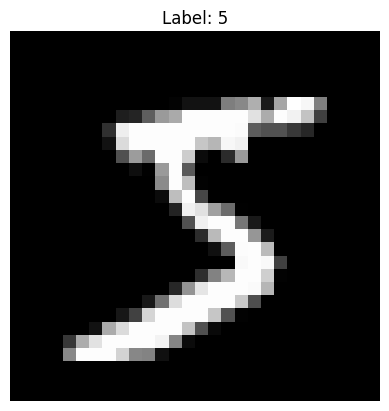

In [6]:
plt.imshow(X_train[0], cmap="gray")
plt.title(f"Label: {y_train[0]}")
plt.axis("off")
plt.show()

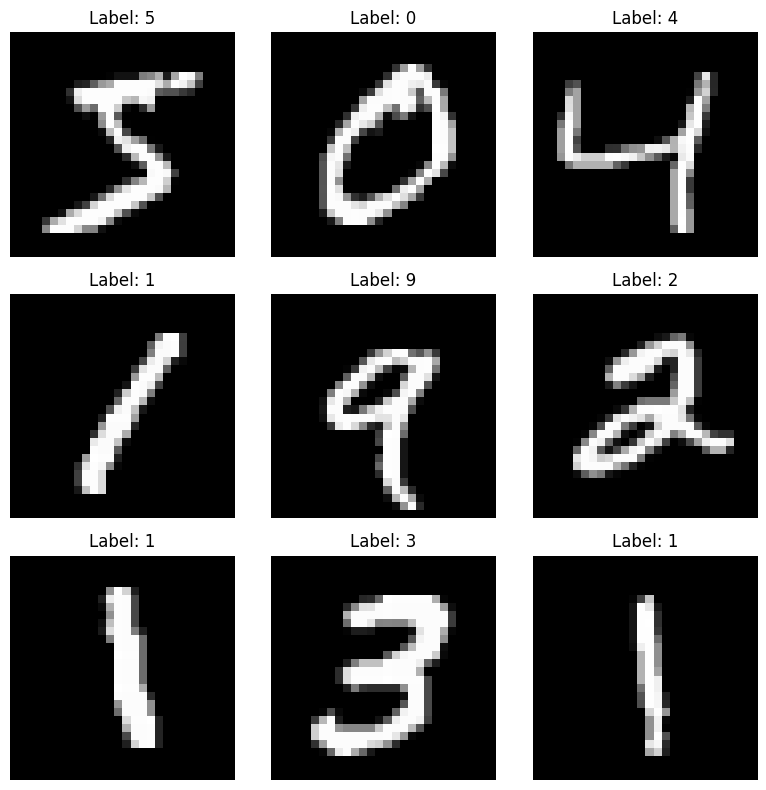

In [7]:
plt.figure(figsize=(8, 8))

for i in range(9):
    plt.subplot(3, 3, i + 1)
    plt.imshow(X_train[i], cmap="gray")
    plt.title(f"Label: {y_train[i]}")
    plt.axis("off")

plt.tight_layout()
plt.show()

In [8]:
print(X_train[0])

[[  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   3  18  18  18 126 136
  175  26 166 255 247 127   0   0   0   0]
 [  0   0   0   0   0   0   0   0  30  36  94 154 170 253 253 253 253 253
  225 172 253 242 195  64   0   0   0   0]
 [  0   0   0   0   0   0   0  49 238 253 253 253 253 253 253 253 253 251
   93  82  82  56  39   0   0   0   0   0]
 [  0   0   0   0   0   0   0  18 219 253 253 253 253 253 198 18

In [9]:
print(X_train[0].min())
print(X_train[0].max())

0
255


In [10]:
X_train = X_train.astype("float32") / 255.0
X_test = X_test.astype("float32") / 255.0

In [11]:
print(X_train[0].min())
print(X_train[0].max())

0.0
1.0


In [12]:
X_train = X_train.reshape(-1, 28, 28, 1)
X_test = X_test.reshape(-1, 28, 28, 1)

In [13]:
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

X_train: (60000, 28, 28, 1)
X_test: (10000, 28, 28, 1)


In [14]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense

In [15]:
model = Sequential([
    
    # Convolution Block 1
    Conv2D(
        filters=32,
        kernel_size=(3, 3),
        activation='relu',
        input_shape=(28, 28, 1)
    ),
    
    MaxPooling2D(pool_size=(2, 2)),
    
    
    # Convolution Block 2
    Conv2D(
        filters=64,
        kernel_size=(3, 3),
        activation='relu'
    ),
    
    MaxPooling2D(pool_size=(2, 2)),
    
    
    # Classification Block
    Flatten(),
    
    Dense(128, activation='relu'),
    
    Dense(10, activation='softmax')
])

In [16]:
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_2 (Conv2D)               │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

In [17]:
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [18]:
history = model.fit(
    X_train,
    y_train,
    epochs=10,
    validation_split=0.2
)

Epoch 1/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 28s 18ms/step - accuracy: 0.9565 - loss: 0.1414 - val_accuracy: 0.9830 - val_loss: 0.0583
Epoch 2/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 26s 17ms/step - accuracy: 0.9857 - loss: 0.0467 - val_accuracy: 0.9876 - val_loss: 0.0431
Epoch 3/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 26s 17ms/step - accuracy: 0.9902 - loss: 0.0305 - val_accuracy: 0.9888 - val_loss: 0.0368
Epoch 4/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 26s 17ms/step - accuracy: 0.9933 - loss: 0.0215 - val_accuracy: 0.9869 - val_loss: 0.0477
Epoch 5/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 26s 17ms/step - accuracy: 0.9944 - loss: 0.0168 - val_accuracy: 0.9877 - val_loss: 0.0486
Epoch 6/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 26s 17ms/step - accuracy: 0.9964 - loss: 0.0115 - val_accuracy: 0.9884 - val_loss: 0.0447
Epoch 7/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 26s 17ms/step - accuracy: 0.9970 - loss: 0.0089 - val_accuracy: 0.9886 - val_loss: 0.0511
Epoch 8/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 26s 17ms/step - accuracy: 0.9970 -

In [19]:
test_loss, test_accuracy = model.evaluate(
    X_test,
    y_test
)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9901 - loss: 0.0449
Test Loss: 0.04487217217683792
Test Accuracy: 0.9901000261306763


In [20]:
predictions = model.predict(X_test)
Dense(10, activation='softmax')
print(predictions[0])

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step
[3.7014974e-14 2.2621663e-14 3.7748054e-14 2.1909407e-14 6.5556055e-17
 4.5165077e-17 1.8202457e-17 1.0000000e+00 9.3997379e-13 8.4686758e-10]


In [21]:
predicted_digit = np.argmax(predictions[0])

print("Predicted:", predicted_digit)
print("Actual:", y_test[0])

Predicted: 7
Actual: 7


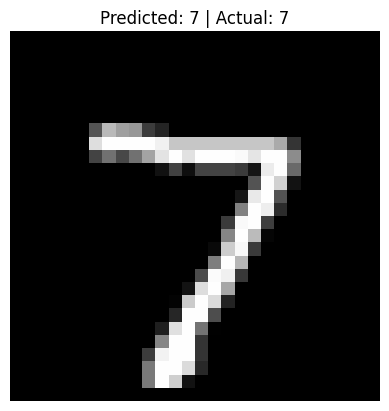

In [22]:
plt.imshow(X_test[0].squeeze(), cmap="gray")

plt.title(
    f"Predicted: {np.argmax(predictions[0])} | Actual: {y_test[0]}"
)

plt.axis("off")
plt.show()

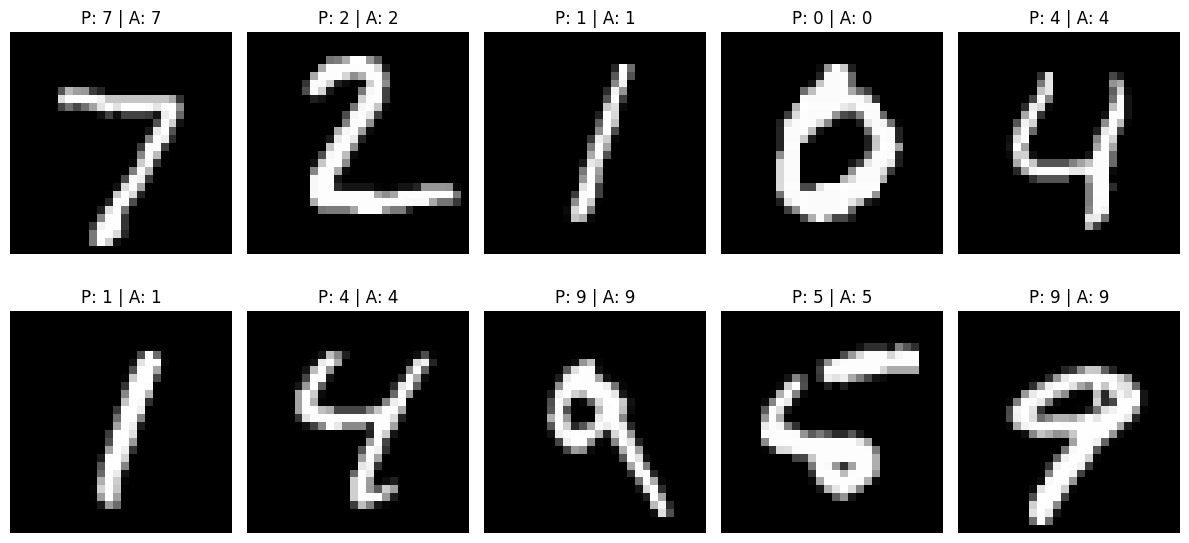

In [23]:
plt.figure(figsize=(12, 6))

for i in range(10):

    plt.subplot(2, 5, i + 1)

    plt.imshow(X_test[i].squeeze(), cmap="gray")

    predicted = np.argmax(predictions[i])
    actual = y_test[i]

    plt.title(f"P: {predicted} | A: {actual}")
    plt.axis("off")

plt.tight_layout()
plt.show()

In [24]:
y_pred = np.argmax(predictions, axis=1)

In [25]:
print(y_pred[:10])
print(y_test[:10])

[7 2 1 0 4 1 4 9 5 9]
[7 2 1 0 4 1 4 9 5 9]


In [26]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

In [27]:
cm = confusion_matrix(y_test, y_pred)

print(cm)

[[ 978    0    0    0    0    0    1    1    0    0]
 [   0 1134    0    0    0    0    0    1    0    0]
 [   3    0 1022    0    0    0    1    5    1    0]
 [   2    1    2  997    0    1    0    0    7    0]
 [   0    0    0    0  975    0    1    0    0    6]
 [   2    0    1    5    0  871    4    1    6    2]
 [   4    2    0    0    2    2  947    0    1    0]
 [   0    1    5    0    1    0    0 1018    1    2]
 [   5    1    0    0    1    0    0    0  966    1]
 [   0    1    1    1    5    0    0    1    7  993]]


<Figure size 1000x800 with 0 Axes>

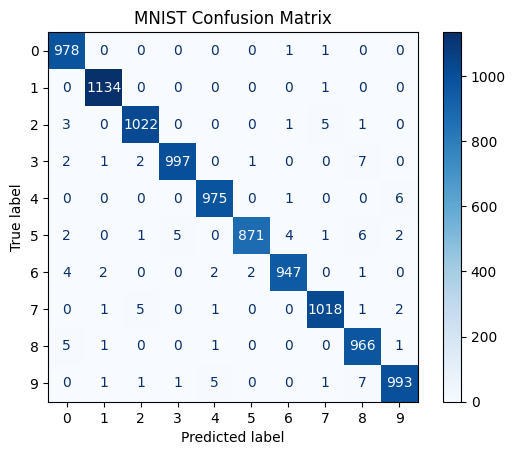

In [28]:
plt.figure(figsize=(10, 8))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=range(10)
)

disp.plot(cmap="Blues")

plt.title("MNIST Confusion Matrix")
plt.show()

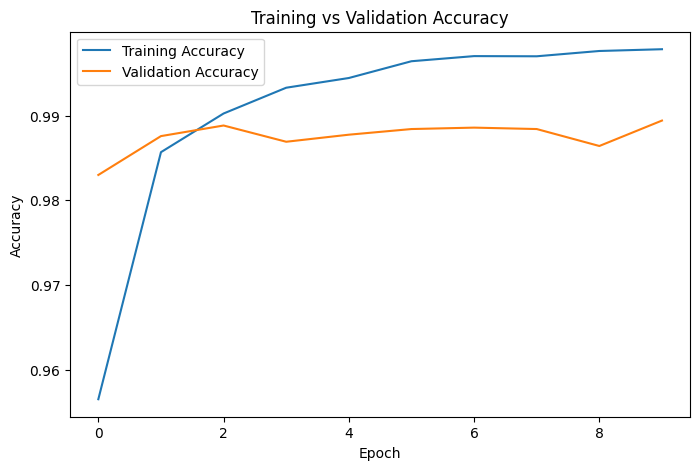

In [29]:
plt.figure(figsize=(8, 5))

plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')

plt.title('Training vs Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')

plt.legend()
plt.show()

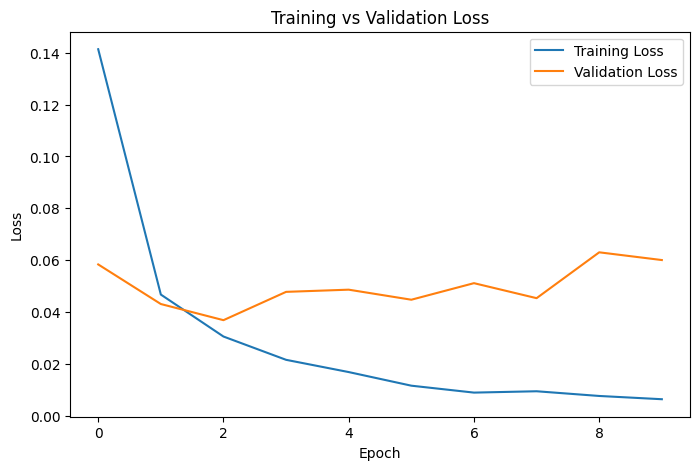

In [30]:
plt.figure(figsize=(8, 5))

plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.title('Training vs Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')

plt.legend()
plt.show()

In [31]:
from tensorflow.keras.layers import Dropout

model_dropout = Sequential([

    Conv2D(32, (3,3), activation='relu', input_shape=(28,28,1)),
    MaxPooling2D((2,2)),

    Conv2D(64, (3,3), activation='relu'),
    MaxPooling2D((2,2)),

    Dropout(0.25),

    Flatten(),

    Dense(128, activation='relu'),

    Dropout(0.5),

    Dense(10, activation='softmax')
])

/home/kniti/Downloads/ADS/myenv/lib/python3.12/site-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [32]:
model_dropout.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [33]:
history_dropout = model_dropout.fit(
    X_train,
    y_train,
    epochs=10,
    validation_split=0.2
)

Epoch 1/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 20s 13ms/step - accuracy: 0.9256 - loss: 0.2377 - val_accuracy: 0.9831 - val_loss: 0.0569
Epoch 2/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 23s 15ms/step - accuracy: 0.9725 - loss: 0.0928 - val_accuracy: 0.9853 - val_loss: 0.0486
Epoch 3/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 27s 18ms/step - accuracy: 0.9783 - loss: 0.0705 - val_accuracy: 0.9885 - val_loss: 0.0383
Epoch 4/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 27s 18ms/step - accuracy: 0.9818 - loss: 0.0589 - val_accuracy: 0.9886 - val_loss: 0.0388
Epoch 5/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 27s 18ms/step - accuracy: 0.9851 - loss: 0.0495 - val_accuracy: 0.9909 - val_loss: 0.0337
Epoch 6/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 20s 14ms/step - accuracy: 0.9856 - loss: 0.0471 - val_accuracy: 0.9893 - val_loss: 0.0360
Epoch 7/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 27s 18ms/step - accuracy: 0.9870 - loss: 0.0412 - val_accuracy: 0.9902 - val_loss: 0.0339
Epoch 8/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 27s 18ms/step - accuracy: 0.9888 -

In [34]:
history_dropout

In [35]:
history

In [36]:
test_loss_dropout, test_accuracy_dropout = model_dropout.evaluate(
    X_test,
    y_test
)

print("Dropout Test Loss:", test_loss_dropout)
print("Dropout Test Accuracy:", test_accuracy_dropout)

313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.9924 - loss: 0.0240
Dropout Test Loss: 0.023954587057232857
Dropout Test Accuracy: 0.9923999905586243


In [37]:
model_dropout.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [38]:
history_dropout = model_dropout.fit(
    X_train,
    y_train,
    epochs=10,
    validation_split=0.2
)

Epoch 1/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 28s 18ms/step - accuracy: 0.9900 - loss: 0.0303 - val_accuracy: 0.9923 - val_loss: 0.0312
Epoch 2/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 27s 18ms/step - accuracy: 0.9915 - loss: 0.0277 - val_accuracy: 0.9920 - val_loss: 0.0370
Epoch 3/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 27s 18ms/step - accuracy: 0.9926 - loss: 0.0242 - val_accuracy: 0.9918 - val_loss: 0.0367
Epoch 4/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 27s 18ms/step - accuracy: 0.9918 - loss: 0.0266 - val_accuracy: 0.9923 - val_loss: 0.0339
Epoch 5/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 22s 15ms/step - accuracy: 0.9923 - loss: 0.0243 - val_accuracy: 0.9922 - val_loss: 0.0334
Epoch 6/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 26s 17ms/step - accuracy: 0.9930 - loss: 0.0209 - val_accuracy: 0.9918 - val_loss: 0.0405
Epoch 7/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 26s 18ms/step - accuracy: 0.9930 - loss: 0.0210 - val_accuracy: 0.9919 - val_loss: 0.0359
Epoch 8/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 26s 18ms/step - accuracy: 0.9930 -

In [39]:
test_loss_dropout, test_accuracy_dropout = model_dropout.evaluate(
    X_test,
    y_test
)

print("Dropout Test Accuracy:", test_accuracy_dropout)

313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.9923 - loss: 0.0345
Dropout Test Accuracy: 0.9922999739646912


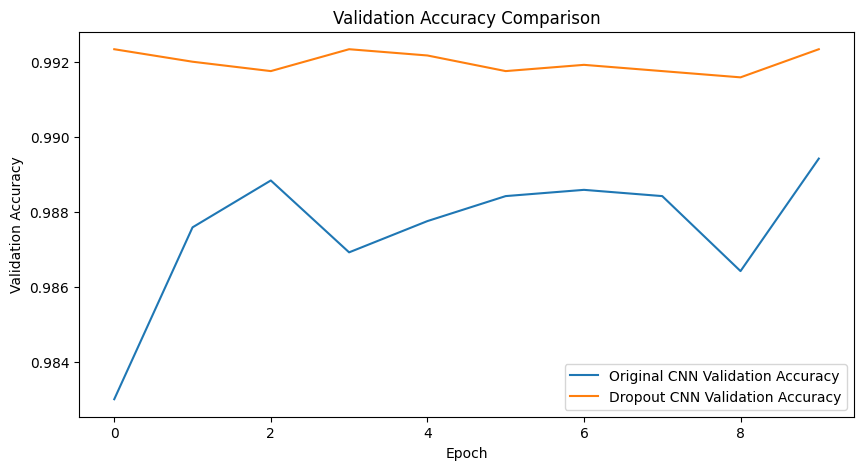

In [40]:
plt.figure(figsize=(10, 5))

plt.plot(
    history.history['val_accuracy'],
    label='Original CNN Validation Accuracy'
)

plt.plot(
    history_dropout.history['val_accuracy'],
    label='Dropout CNN Validation Accuracy'
)

plt.title('Validation Accuracy Comparison')
plt.xlabel('Epoch')
plt.ylabel('Validation Accuracy')

plt.legend()
plt.show()

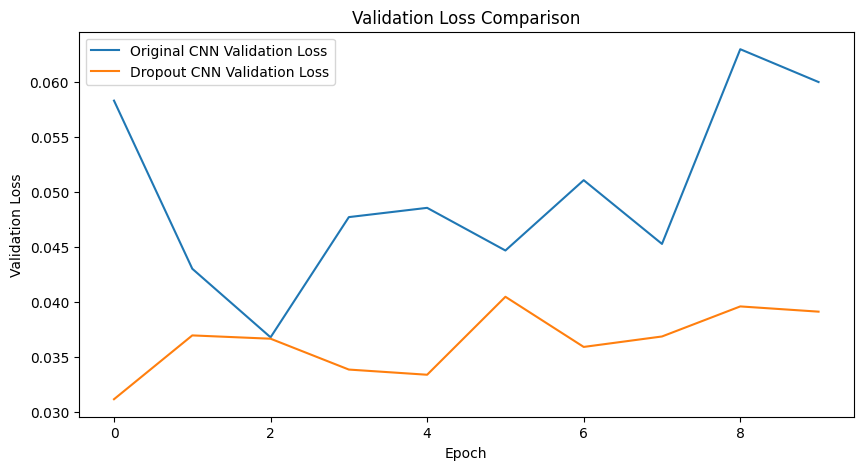

In [41]:
plt.figure(figsize=(10, 5))

plt.plot(
    history.history['val_loss'],
    label='Original CNN Validation Loss'
)

plt.plot(
    history_dropout.history['val_loss'],
    label='Dropout CNN Validation Loss'
)

plt.title('Validation Loss Comparison')
plt.xlabel('Epoch')
plt.ylabel('Validation Loss')

plt.legend()
plt.show()

In [42]:
print(f"Original CNN Test Accuracy: {test_accuracy * 100:.2f}%")
print(f"Dropout CNN Test Accuracy: {test_accuracy_dropout * 100:.2f}%")

Original CNN Test Accuracy: 99.01%
Dropout CNN Test Accuracy: 99.23%


In [43]:
from tensorflow.keras.layers import BatchNormalization, Activation

model_bn = Sequential([

    Conv2D(32, (3,3), input_shape=(28,28,1)),
    BatchNormalization(),
    Activation('relu'),
    MaxPooling2D((2,2)),

    Conv2D(64, (3,3)),
    BatchNormalization(),
    Activation('relu'),
    MaxPooling2D((2,2)),

    Flatten(),

    Dense(128),
    BatchNormalization(),
    Activation('relu'),

    Dense(10, activation='softmax')
])

In [44]:
from tensorflow.keras.layers import BatchNormalization, Activation

model_bn = Sequential([

    Conv2D(32, (3,3), input_shape=(28,28,1)),
    BatchNormalization(),
    Activation('relu'),
    MaxPooling2D((2,2)),

    Conv2D(64, (3,3)),
    BatchNormalization(),
    Activation('relu'),
    MaxPooling2D((2,2)),

    Flatten(),

    Dense(128),
    BatchNormalization(),
    Activation('relu'),

    Dense(10, activation='softmax')
])

In [45]:
model_bn.summary()

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_8 (Conv2D)               │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 26, 26, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 26, 26, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_8 (MaxPooling2D)  │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 11, 11, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_4 (Activation)       │ (None, 11, 11, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_9 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_4 (Flatten)             │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_5 (Activation)       │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225,930 (882.54 KB)

 Trainable params: 225,482 (880.79 KB)

 Non-trainable params: 448 (1.75 KB)

In [46]:
model_bn.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [47]:
model_bn.summary()

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_8 (Conv2D)               │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 26, 26, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 26, 26, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_8 (MaxPooling2D)  │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 11, 11, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_4 (Activation)       │ (None, 11, 11, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_9 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_4 (Flatten)             │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_5 (Activation)       │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225,930 (882.54 KB)

 Trainable params: 225,482 (880.79 KB)

 Non-trainable params: 448 (1.75 KB)

In [48]:
history_bn = model_bn.fit(
    X_train,
    y_train,
    epochs=10,
    validation_split=0.2
)

Epoch 1/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 39s 25ms/step - accuracy: 0.9710 - loss: 0.1019 - val_accuracy: 0.9839 - val_loss: 0.0511
Epoch 2/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 41s 28ms/step - accuracy: 0.9869 - loss: 0.0428 - val_accuracy: 0.9883 - val_loss: 0.0418
Epoch 3/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 35s 24ms/step - accuracy: 0.9905 - loss: 0.0317 - val_accuracy: 0.9870 - val_loss: 0.0430
Epoch 4/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 42s 28ms/step - accuracy: 0.9930 - loss: 0.0228 - val_accuracy: 0.9858 - val_loss: 0.0475
Epoch 5/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 41s 27ms/step - accuracy: 0.9943 - loss: 0.0167 - val_accuracy: 0.9892 - val_loss: 0.0396
Epoch 6/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 41s 28ms/step - accuracy: 0.9950 - loss: 0.0153 - val_accuracy: 0.9895 - val_loss: 0.0392
Epoch 7/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 40s 26ms/step - accuracy: 0.9958 - loss: 0.0129 - val_accuracy: 0.9895 - val_loss: 0.0355
Epoch 8/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 42s 28ms/step - accuracy: 0.9975 -

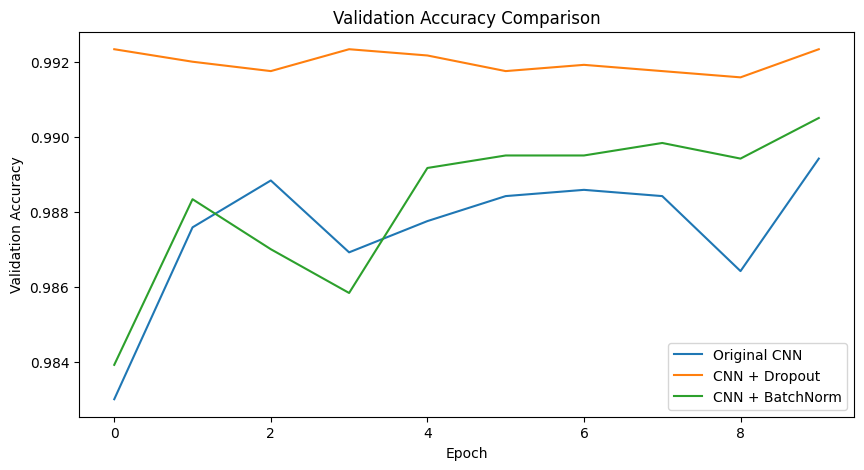

In [49]:
plt.figure(figsize=(10, 5))

plt.plot(
    history.history['val_accuracy'],
    label='Original CNN'
)

plt.plot(
    history_dropout.history['val_accuracy'],
    label='CNN + Dropout'
)

plt.plot(
    history_bn.history['val_accuracy'],
    label='CNN + BatchNorm'
)

plt.title('Validation Accuracy Comparison')
plt.xlabel('Epoch')
plt.ylabel('Validation Accuracy')

plt.legend()
plt.show()

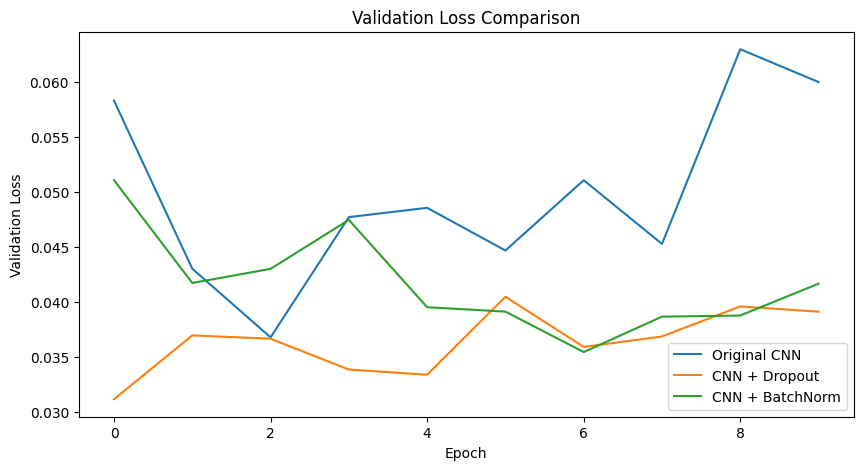

In [50]:
plt.figure(figsize=(10, 5))

plt.plot(
    history.history['val_loss'],
    label='Original CNN'
)

plt.plot(
    history_dropout.history['val_loss'],
    label='CNN + Dropout'
)

plt.plot(
    history_bn.history['val_loss'],
    label='CNN + BatchNorm'
)

plt.title('Validation Loss Comparison')
plt.xlabel('Epoch')
plt.ylabel('Validation Loss')

plt.legend()
plt.show()

In [52]:
print(f"Original CNN: {test_accuracy * 100:.2f}%")
print(f"CNN + Dropout: {test_accuracy_dropout * 100:.2f}%")
#print(f"CNN + BatchNorm: {test_accuracy_bn * 100:.2f}%")

Original CNN: 99.01%
CNN + Dropout: 99.23%


In [53]:
from tensorflow.keras import layers

data_augmentation = tf.keras.Sequential([
    layers.RandomRotation(0.1),
    layers.RandomTranslation(0.1, 0.1),
    layers.RandomZoom(0.1)
])

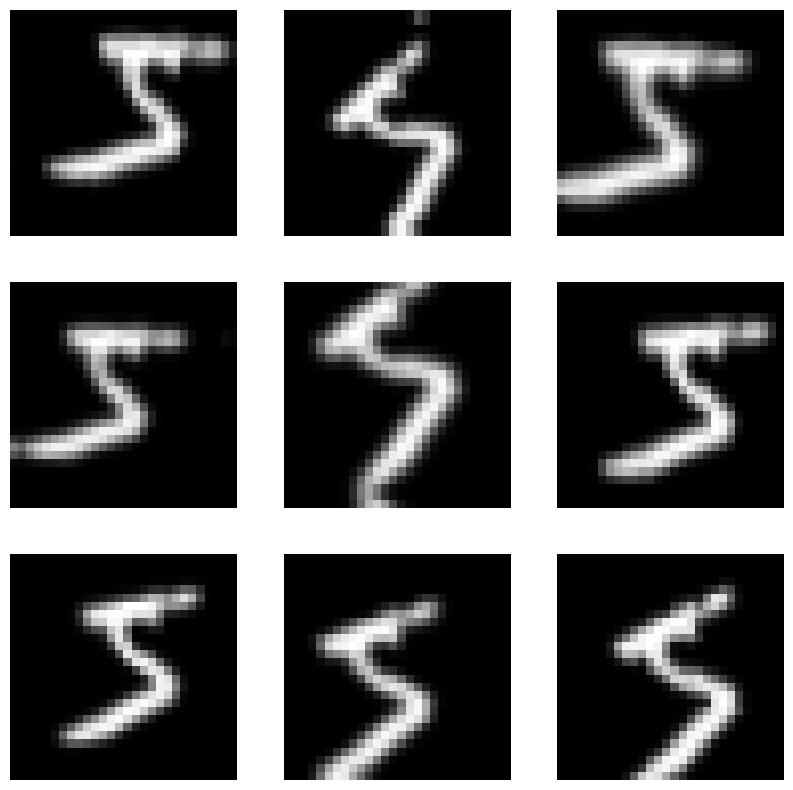

In [54]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 10))

# Take one training image
image = X_train[0]

for i in range(9):

    augmented_image = data_augmentation(
        tf.expand_dims(image, 0)
    )

    plt.subplot(3, 3, i + 1)

    plt.imshow(
        augmented_image[0],
        cmap='gray'
    )

    plt.axis('off')

plt.show()

In [55]:
data_augmentation = tf.keras.Sequential([

    layers.RandomRotation(0.05),

    layers.RandomTranslation(
        height_factor=0.05,
        width_factor=0.05
    ),

    layers.RandomZoom(0.05)

])

In [56]:
model_aug = tf.keras.Sequential([

    data_augmentation,

    layers.Conv2D(
        32,
        (3, 3),
        activation='relu',
        input_shape=(28, 28, 1)
    ),

    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(
        64,
        (3, 3),
        activation='relu'
    ),

    layers.MaxPooling2D((2, 2)),

    layers.Flatten(),

    layers.Dense(
        128,
        activation='relu'
    ),

    layers.Dense(
        10,
        activation='softmax'
    )
])

In [57]:
model_aug.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)
history_aug = model_aug.fit(
    X_train,
    y_train,
    epochs=15,
    validation_split=0.2
)

Epoch 1/15
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 43s 26ms/step - accuracy: 0.9287 - loss: 0.2277 - val_accuracy: 0.9815 - val_loss: 0.0584
Epoch 2/15
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 17s 11ms/step - accuracy: 0.9732 - loss: 0.0865 - val_accuracy: 0.9841 - val_loss: 0.0518
Epoch 3/15
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 8s 6ms/step - accuracy: 0.9797 - loss: 0.0641 - val_accuracy: 0.9860 - val_loss: 0.0449
Epoch 4/15
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 14s 9ms/step - accuracy: 0.9825 - loss: 0.0538 - val_accuracy: 0.9887 - val_loss: 0.0378
Epoch 5/15
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 9s 6ms/step - accuracy: 0.9849 - loss: 0.0481 - val_accuracy: 0.9899 - val_loss: 0.0388
Epoch 6/15
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 10s 6ms/step - accuracy: 0.9866 - loss: 0.0425 - val_accuracy: 0.9862 - val_loss: 0.0517
Epoch 7/15
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 10s 6ms/step - accuracy: 0.9879 - loss: 0.0369 - val_accuracy: 0.9906 - val_loss: 0.0342
Epoch 8/15
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 10s 7ms/step - accuracy: 0.9889 - loss: 0

In [58]:
test_loss_aug, test_accuracy_aug = model_aug.evaluate(
    X_test,
    y_test
)

print(f"Augmented CNN Test Accuracy: {test_accuracy_aug * 100:.2f}%")

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9935 - loss: 0.0238
Augmented CNN Test Accuracy: 99.35%


In [ ]:
print(f"Original CNN:        {test_accuracy * 100:.2f}%")
print(f"CNN + Dropout:       {test_accuracy_dropout * 100:.2f}%")
#print(f"CNN + BatchNorm:     {test_accuracy_bn * 100:.2f}%")
print(f"CNN + Augmentation:  {test_accuracy_aug * 100:.2f}%")

Original CNN:        99.08%
CNN + Dropout:       99.30%
CNN + Augmentation:  99.19%


In [ ]:
import tensorflow as tf
from tensorflow.keras import layers

def build_model():

    model = tf.keras.Sequential([
        layers.Conv2D(32, (3,3), activation='relu',
                      input_shape=(28,28,1)),
        layers.MaxPooling2D((2,2)),

        layers.Conv2D(64, (3,3), activation='relu'),
        layers.MaxPooling2D((2,2)),

        layers.Flatten(),

        layers.Dense(128, activation='relu'),

        layers.Dense(10, activation='softmax')
    ])

    return model

I0000 00:00:1789057315.255825    8009 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1789057315.256416    8009 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1789057315.316207    8009 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1789057317.017629    8009 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.

In [59]:
learning_rates = [0.1, 0.01, 0.001, 0.0001]

histories = {}

for lr in learning_rates:

    print(f"\nTraining with learning rate = {lr}")

    model = build_model()

    optimizer = tf.keras.optimizers.Adam(
        learning_rate=lr
    )

    model.compile(
        optimizer=optimizer,
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )

    history = model.fit(
        X_train,
        y_train,
        epochs=5,
        validation_split=0.2,
        verbose=1
    )

    histories[lr] = history


Training with learning rate = 0.1
Epoch 1/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.1013 - loss: 3.0778 - val_accuracy: 0.0998 - val_loss: 2.3109
Epoch 2/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.1047 - loss: 2.3133 - val_accuracy: 0.1060 - val_loss: 2.3169
Epoch 3/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.1042 - loss: 2.3138 - val_accuracy: 0.0998 - val_loss: 2.3157
Epoch 4/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.1046 - loss: 2.3130 - val_accuracy: 0.1060 - val_loss: 2.3086
Epoch 5/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.1028 - loss: 2.3133 - val_accuracy: 0.1060 - val_loss: 2.3119

Training with learning rate = 0.01
Epoch 1/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - accuracy: 0.9438 - loss: 0.1783 - val_accuracy: 0.9725 - val_loss: 0.0867
Epoch 2/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9715 - loss: 0.0966 - val_accuracy: 0.9649 - val_loss: 0.1216
Epoch 3/5
1500/1500 ━━━━━━

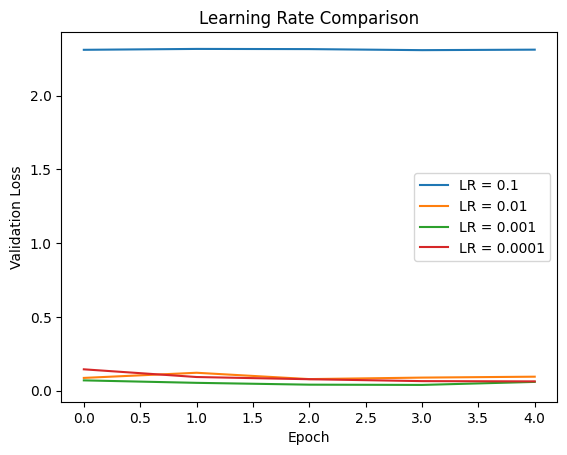

In [60]:
import matplotlib.pyplot as plt

for lr in learning_rates:

    plt.plot(
        histories[lr].history['val_loss'],
        label=f"LR = {lr}"
    )

plt.xlabel("Epoch")
plt.ylabel("Validation Loss")
plt.title("Learning Rate Comparison")
plt.legend()
plt.show()